# Session 13.1: Loading Images with Datasets and Transforms

**Learning goals:**

- Explain how ImageFolder assigns labels from class subfolders.
- Combine Grayscale, Resize and ToTensor with Compose.
- Retrieve an image-label pair and verify the tensor shape required by a CNN.

**Prerequisites:**

- Basic Python and CNN model construction.
- Python with PyTorch.
- Code in Google Colab.


## Outline

0. Review: from image files to CNN inputs
1. ImageFolder and image transforms
2. Live Coding
3. Hands-on Notebook
4. Check for Understanding


## 0. From Image Files to CNN Inputs

A CNN receives numeric tensors. Image files may have different dimensions and colour modes.
Before batching them, we prepare a consistent channel count, height and width.

**Think:** two pictures show the digit 1, but one is 28 × 28 pixels and the other is 36 × 32.
How can the same CNN process both?

![Image files are resized and converted to single-channel tensors, then batched for a CNN.](assets/session13-image-to-cnn-pipeline.png)


## 1. ImageFolder and Image Transforms


### 1.1 Organise images by class

[Download the digit images ZIP](assets/digit_images.zip){download="digit_images.zip"}

ImageFolder expects a root directory containing one subfolder per class.
It sorts class names and assigns an integer index to each. Always inspect the mapping;
a class index is not automatically the same as a digit written in a folder name.

```text
sample_data/digit_images/
    0/
        mnist-row-00005.png
        ...
    1/
        ...
    2/
        ...
    3/
        ...
    4/
        ...
    5/
        ...
    6/
        ...
    7/
        ...
    8/
        ...
    9/
        ...
```

The ten folders represent digits 0–9, with 24 images in each folder.

ImageFolder stores file paths and labels. It opens and transforms an image when you request
a sample; creating the dataset does not load every transformed image into memory.

[Official documentation: ImageFolder](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)


### 1.2 Apply transforms in order

| Transform | Purpose | Result for this lesson |
|---|---|---|
| `Grayscale(1)` | Set the number of channels | One intensity channel |
| `Resize((28, 28))` | Standardise height and width | 28 × 28 pixels |
| `ToTensor()` | Convert a PIL image to a tensor | Float tensor in channel-first order |
| `Compose([...])` | Apply the listed steps in sequence | One reusable pipeline |

For the supplied 8-bit images, ToTensor scales pixels from 0–255 to 0–1.
This scaling is different from `Normalize(mean, std)`, which standardises values using channel statistics.
In this pipeline, Resize receives a PIL image before ToTensor runs.

[Official documentation: image transforms](https://docs.pytorch.org/vision/stable/transforms.html)

Build the pipeline and attach it to ImageFolder. The class list should contain all ten digits.


In [9]:
from torchvision import datasets, transforms

DIGIT_ROOT = "sample_data/digit_images"
IMAGE_SIZE = (28, 28)

digit_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # Keep one intensity channel.
    transforms.Resize(IMAGE_SIZE),  # Use the height and width expected by the CNN.
    transforms.ToTensor(),  # Convert uint8 pixels to float values in [0, 1].
])
full_dataset = datasets.ImageFolder(DIGIT_ROOT, transform=digit_transform)  # Apply transforms when retrieving a sample.
print("Images:", len(full_dataset))
print("Classes:", full_dataset.classes)
print("Class mapping:", full_dataset.class_to_idx)


Images: 240
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}


## 2. Live Coding

Display five images of digit 0 and compare their original sizes (width, height).


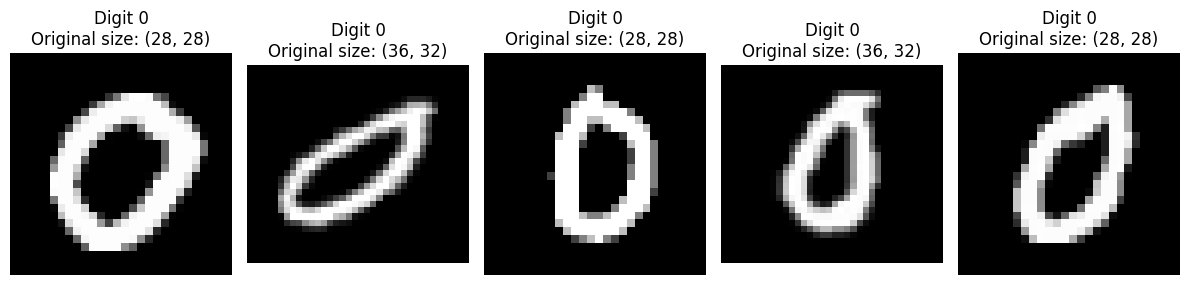

In [10]:
import os
from PIL import Image
import matplotlib.pyplot as plt

source_folder = "sample_data/digit_images/0"
NUMBER_OF_IMAGES = 5
source_names = sorted(name for name in os.listdir(source_folder) if name.endswith(".png"))
figure, axes = plt.subplots(1, NUMBER_OF_IMAGES, figsize=(12, 3))  # Show five original digit images.
for axis, filename in zip(axes, source_names[:NUMBER_OF_IMAGES]):
    with Image.open(os.path.join(source_folder, filename)) as original:  # Read the source image before transforms.
        axis.imshow(original, cmap="gray", vmin=0, vmax=255)  # Use the original 8-bit pixel range.
        axis.set_title(f"Digit 0\nOriginal size: {original.size}")  # PIL reports (width, height).
    axis.axis("off")
plt.tight_layout()
plt.show()


Prepare one greyscale channel, resize to 28 × 28 and convert pixels to a tensor.
Attach the transforms to ImageFolder.


In [11]:
from torchvision import datasets, transforms

DIGIT_ROOT = "sample_data/digit_images"
IMAGE_SIZE = (28, 28)

digit_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # Keep one intensity channel.
    transforms.Resize(IMAGE_SIZE),  # Use the height and width expected by the CNN.
    transforms.ToTensor(),  # Convert uint8 pixels to float values in [0, 1].
])
full_dataset = datasets.ImageFolder(DIGIT_ROOT, transform=digit_transform)  # Apply transforms when retrieving a sample.
print("Images:", len(full_dataset))
print("Classes:", full_dataset.classes)
print("Class mapping:", full_dataset.class_to_idx)


Images: 240
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}


Check one transformed image. Its shape should be `[1, 28, 28]`: channels, height and width.


In [12]:
image, label = full_dataset[0]  # Retrieve one transformed image and its class label.
print("Digit:", full_dataset.classes[label])
print("Tensor shape:", tuple(image.shape))  # Read the dimensions as channels, height and width.


Digit: 0
Tensor shape: (1, 28, 28)


## 3. Hands-on Notebook

[Download the practice notebook](<Session13.1 Load Digit Images Practice.ipynb>){download="Session13.1 Load Digit Images Practice.ipynb"}

[Download the digit images](assets/digit_images.zip){download="digit_images.zip"}

1. Download both files and open the notebook in [Google Colab](https://colab.research.google.com/) using **File → Upload notebook**.
2. Click **Connect**. A CPU runtime is sufficient.
3. Upload `digit_images.zip` through the **Files** sidebar, then follow Section 1 to extract it.
4. Complete the transforms and ImageFolder code in Section 2, then run the remaining cells in order to inspect tensors, train the CNN and view predictions.

Check that one image has shape `[1, 28, 28]` and the test output has shape `[48, 10]`.


## 4. Check for Understanding

1. What do the three values in `[1, 28, 28]` represent?
2. Where does the label come from?
3. How would the channel count change if we kept RGB images?

Continue with [Session 13.2: Preparing Image Batches for a CNN Model](<Session13.2 Preparing Image Batches for a CNN Model.ipynb>).
